# DSCI 552 — Homework 7

**Name:** Yuanda SHI  
**USC ID:** 6635-4638-05

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import (
    SVC,
    LinearSVC
)

from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    accuracy_score,
    calinski_harabasz_score
)

from sklearn.cluster import KMeans

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from scipy.cluster.hierarchy import dendrogram

from IPython.display import display

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

In [2]:
PROJECT_ROOT = Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "Frogs_MFCCs.csv"

assert DATA_PATH.is_file(), (
    f"Missing dataset: {DATA_PATH.resolve()}"
)

frogs_df = pd.read_csv(
    DATA_PATH
)

print(
    "Dataset shape:",
    frogs_df.shape
)

display(
    frogs_df.head()
)

print("\nColumns:")
print(frogs_df.columns.tolist())

Dataset shape: (7195, 26)


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1



Columns:
['MFCCs_ 1', 'MFCCs_ 2', 'MFCCs_ 3', 'MFCCs_ 4', 'MFCCs_ 5', 'MFCCs_ 6', 'MFCCs_ 7', 'MFCCs_ 8', 'MFCCs_ 9', 'MFCCs_10', 'MFCCs_11', 'MFCCs_12', 'MFCCs_13', 'MFCCs_14', 'MFCCs_15', 'MFCCs_16', 'MFCCs_17', 'MFCCs_18', 'MFCCs_19', 'MFCCs_20', 'MFCCs_21', 'MFCCs_22', 'Family', 'Genus', 'Species', 'RecordID']


In [3]:
LABEL_COLUMNS = [
    "Family",
    "Genus",
    "Species"
]

feature_columns = [
    column
    for column in frogs_df.columns
    if column.startswith("MFCC")
]

print(
    "Number of MFCC features:",
    len(feature_columns)
)

print(
    "Feature columns:",
    feature_columns
)

print("\nLabel class counts:")

for label in LABEL_COLUMNS:
    print(f"\n--- {label} ---")
    print(
        frogs_df[label].value_counts()
    )

print(
    "\nMissing values:",
    frogs_df.isna().sum().sum()
)

assert len(feature_columns) == 22
assert frogs_df.isna().sum().sum() == 0

Number of MFCC features: 22
Feature columns: ['MFCCs_ 1', 'MFCCs_ 2', 'MFCCs_ 3', 'MFCCs_ 4', 'MFCCs_ 5', 'MFCCs_ 6', 'MFCCs_ 7', 'MFCCs_ 8', 'MFCCs_ 9', 'MFCCs_10', 'MFCCs_11', 'MFCCs_12', 'MFCCs_13', 'MFCCs_14', 'MFCCs_15', 'MFCCs_16', 'MFCCs_17', 'MFCCs_18', 'MFCCs_19', 'MFCCs_20', 'MFCCs_21', 'MFCCs_22']

Label class counts:

--- Family ---
Family
Leptodactylidae    4420
Hylidae            2165
Dendrobatidae       542
Bufonidae            68
Name: count, dtype: int64

--- Genus ---
Genus
Adenomera        4150
Hypsiboas        1593
Ameerega          542
Dendropsophus     310
Leptodactylus     270
Scinax            148
Osteocephalus     114
Rhinella           68
Name: count, dtype: int64

--- Species ---
Species
AdenomeraHylaedactylus    3478
HypsiboasCordobae         1121
AdenomeraAndre             672
Ameeregatrivittata         542
HypsiboasCinerascens       472
HylaMinuta                 310
LeptodactylusFuscus        270
ScinaxRuber                148
OsteocephalusOophagus      1

## 1. Multi-Class and Multi-Label Classification Using Support Vector Machines

### 1(a) Train-Test Split

Randomly select 70% of the observations as the training set and
use the remaining 30% as the test set.

Because every observation has three labels, the combined
(Family, Genus, Species) triplet is used for stratification so that
the train and test sets preserve the multilabel class structure.

In [4]:
X = frogs_df[
    feature_columns
].copy()

Y = frogs_df[
    LABEL_COLUMNS
].copy()

combined_label = (
    Y["Family"].astype(str)
    + "|"
    + Y["Genus"].astype(str)
    + "|"
    + Y["Species"].astype(str)
)

(
    X_train,
    X_test,
    Y_train,
    Y_test
) = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=combined_label
)

print(
    "Training observations:",
    len(X_train)
)

print(
    "Test observations:",
    len(X_test)
)

print(
    "Training proportion:",
    len(X_train) / len(X)
)

print(
    "Test proportion:",
    len(X_test) / len(X)
)

Training observations: 5036
Test observations: 2159
Training proportion: 0.6999305072967339
Test proportion: 0.30006949270326616


### 1(b)i Multi-Label Evaluation Metrics

Each observation has three labels:

\[
(\text{Family}, \text{Genus}, \text{Species}).
\]

#### Exact Match

Exact match requires **all three labels** for an observation to be
predicted correctly.

\[
\text{Exact Match}
= \frac{
\text{Number of observations with all labels correct}
}{
n
}.
\]

This is a strict metric because one incorrect label makes the whole
observation incorrect.

#### Hamming Loss

Hamming loss measures the proportion of individual labels that are
predicted incorrectly:

\[
\text{Hamming Loss}
= \frac{
\text{Number of incorrect label predictions}
}{
nL
},
\]

where \(L=3\) is the number of labels.

Lower values are better.

#### Hamming Score

In this homework, the Hamming score is taken as the complement of
Hamming loss:

\[
\text{Hamming Score}
= 1-\text{Hamming Loss}.
\]

Higher values are better.

In [6]:
def evaluate_multilabel(
    y_true,
    y_pred,
    model_name=""
):
    true_array = (
        y_true[LABEL_COLUMNS]
        .astype(str)
        .to_numpy()
    )

    pred_array = (
        y_pred[LABEL_COLUMNS]
        .astype(str)
        .to_numpy()
    )

    match_matrix = (
        true_array == pred_array
    )

    exact_match = (
        np.all(
            match_matrix,
            axis=1
        )
        .mean()
    )

    hamming_loss_value = (
        1
        -
        match_matrix.mean()
    )

    hamming_score_value = (
        match_matrix.mean()
    )

    average_hamming_distance = (
        (~match_matrix)
        .sum(axis=1)
        .mean()
    )

    results = {
        "Model": model_name,
        "Exact Match": exact_match,
        "Hamming Score": hamming_score_value,
        "Hamming Loss": hamming_loss_value,
        "Average Hamming Distance":
            average_hamming_distance
    }

    return results

### 1(b)ii Gaussian-Kernel SVM

A separate multiclass classifier is trained for each label using
the binary relevance approach:

1. Family
2. Genus
3. Species

Each classifier uses:

- Gaussian (RBF) kernel;
- One-vs-Rest classification;
- 10-fold cross-validation.

Both the SVM penalty \(C\) and Gaussian kernel parameter
\(\gamma\) are selected by cross-validation.

The relationship between Gaussian width \(\sigma\) and
\(\gamma\) is

\[
\gamma=\frac{1}{2\sigma^2}.
\]

In [7]:
rbf_C_values = [
    0.1,
    1,
    10,
    100
]

rbf_gamma_values = [
    0.01,
    0.1,
    1,
    10
]


def tune_rbf_svm(
    X_train,
    y_train
):
    cv = StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    classifier = OneVsRestClassifier(
        SVC(
            kernel="rbf"
        ),
        n_jobs=1
    )

    model = Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "classifier",
            classifier
        )
    ])

    param_grid = {
        "classifier__estimator__C":
            rbf_C_values,

        "classifier__estimator__gamma":
            rbf_gamma_values
    }

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(
        X_train,
        y_train
    )

    return grid

In [8]:
rbf_models = {}
rbf_records = []

for label in LABEL_COLUMNS:

    print(
        f"Training RBF SVM for {label}..."
    )

    grid = tune_rbf_svm(
        X_train,
        Y_train[label]
    )

    rbf_models[label] = grid

    best_C = (
        grid.best_params_[
            "classifier__estimator__C"
        ]
    )

    best_gamma = (
        grid.best_params_[
            "classifier__estimator__gamma"
        ]
    )

    gaussian_sigma = np.sqrt(
        1 / (2 * best_gamma)
    )

    test_prediction = (
        grid.predict(
            X_test
        )
    )

    test_accuracy = (
        accuracy_score(
            Y_test[label],
            test_prediction
        )
    )

    rbf_records.append({
        "Label": label,
        "Best C": best_C,
        "Best gamma": best_gamma,
        "Gaussian sigma":
            gaussian_sigma,
        "CV Accuracy":
            grid.best_score_,
        "Test Accuracy":
            test_accuracy
    })


rbf_summary = pd.DataFrame(
    rbf_records
)

display(
    rbf_summary
)

Training RBF SVM for Family...
Training RBF SVM for Genus...
Training RBF SVM for Species...


,Label,Best C,Best gamma,Gaussian sigma,CV Accuracy,Test Accuracy
0,Family,10,0.10,2.236068,0.990269,0.992589
1,Genus,100,0.01,7.071068,0.990666,0.984252
2,Species,100,0.01,7.071068,0.989277,0.981936


In [9]:
rbf_predictions = pd.DataFrame(
    index=Y_test.index
)

for label in LABEL_COLUMNS:
    rbf_predictions[label] = (
        rbf_models[label]
        .predict(
            X_test
        )
    )


rbf_multilabel_results = (
    evaluate_multilabel(
        Y_test,
        rbf_predictions,
        "Gaussian SVM"
    )
)

display(
    pd.DataFrame(
        [rbf_multilabel_results]
    )
)

,Model,Exact Match,Hamming Score,Hamming Loss,Average Hamming Distance
0,Gaussian SVM,0.978231,0.986259,0.013741,0.041223


### 1(b)ii Gaussian-Kernel SVM — Results and Interpretation

The Gaussian-kernel SVM classifiers were trained separately for the three labels:

- Family
- Genus
- Species

The combined multi-label test results are:

| Metric | Result |
|---|---:|
| Exact Match | 0.978231 |
| Hamming Score | 0.986259 |
| Hamming Loss | 0.013741 |
| Average Hamming Distance | 0.041223 |

### Exact Match

The exact-match score is

\[
0.978231.
\]

Therefore, approximately

\[
97.82\%
\]

of the test observations have **all three labels predicted correctly at the same time**.

Because exact match requires Family, Genus, and Species to all be correct for an observation, this is a relatively strict evaluation criterion.

The very high exact-match score indicates that the three Gaussian SVM classifiers work very well together as a multi-label classifier.

---

### Hamming Score

The Hamming score is

\[
0.986259.
\]

This means that approximately

\[
98.63\%
\]

of all individual label predictions are correct.

Since each test observation has three labels, the Hamming score evaluates the predictions at the individual-label level rather than requiring the entire label triplet to be correct.

The fact that the Hamming score is higher than the exact-match score is expected because an observation can receive partial credit when two of its three labels are predicted correctly.

---

### Hamming Loss

The Hamming loss is

\[
0.013741.
\]

Therefore, only approximately

\[
1.37\%
\]

of all individual label predictions are incorrect.

This is a very low error rate and indicates strong classification performance across Family, Genus, and Species.

The relationship

\[
\text{Hamming Score}
= 1-\text{Hamming Loss}
\]

is also satisfied:

\[
1-0.013741
= 0.986259.
\]

---

### Average Hamming Distance

The average Hamming distance is

\[
0.041223.
\]

Since each observation contains three labels, the Hamming distance represents the number of incorrectly predicted labels for each observation.

Thus, on average, the Gaussian SVM makes only about

\[
0.041
\]

label errors per test observation.

Equivalently, the average number of correctly predicted labels per observation is approximately

\[
3-0.041223
= 2.958777.
\]

Therefore, nearly all three labels are predicted correctly for a typical observation.

---

### Overall Interpretation

The Gaussian SVM provides excellent performance for this multi-class, multi-label classification problem.

The model achieves:

\[
\boxed{\text{Exact Match}=97.82\%}
\]

and

\[
\boxed{\text{Hamming Score}=98.63\%}.
\]

At the same time, the Hamming loss is only

\[
\boxed{1.37\%}.
\]

These results indicate that the MFCC features contain strong information for distinguishing the frog Family, Genus, and Species labels.

The Gaussian kernel is also capable of modeling nonlinear decision boundaries, which appears to be effective for this dataset.

### Conclusion

The binary-relevance approach using Gaussian SVMs performs extremely well on the test set.

Most observations have their complete Family–Genus–Species label triplet predicted correctly, and errors at the individual-label level are rare.

The next step is to compare these results with the L1-penalized linear SVM to determine whether the simpler sparse linear model can achieve comparable performance.


### 1(b)iii L1-Penalized SVM

Repeat the multi-label classification using L1-penalized
linear support vector machines.

The predictors are standardized before fitting the classifier.

For each label, the SVM penalty \(C\) is selected using 10-fold
cross-validation.

In [10]:
l1_C_values = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100
]


def tune_l1_svm(
    X_train,
    y_train
):
    cv = StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    base_classifier = (
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=30000,
            random_state=RANDOM_STATE
        )
    )

    classifier = (
        OneVsRestClassifier(
            base_classifier,
            n_jobs=1
        )
    )

    model = Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "classifier",
            classifier
        )
    ])

    param_grid = {
        "classifier__estimator__C":
            l1_C_values
    }

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        grid.fit(
            X_train,
            y_train
        )

    return grid

In [11]:
l1_models = {}
l1_records = []

for label in LABEL_COLUMNS:

    print(
        f"Training L1 SVM for {label}..."
    )

    grid = tune_l1_svm(
        X_train,
        Y_train[label]
    )

    l1_models[label] = grid

    best_C = (
        grid.best_params_[
            "classifier__estimator__C"
        ]
    )

    prediction = (
        grid.predict(
            X_test
        )
    )

    test_accuracy = (
        accuracy_score(
            Y_test[label],
            prediction
        )
    )

    l1_records.append({
        "Label": label,
        "Best C": best_C,
        "CV Accuracy":
            grid.best_score_,
        "Test Accuracy":
            test_accuracy
    })


l1_summary = pd.DataFrame(
    l1_records
)

display(
    l1_summary
)

Training L1 SVM for Family...
Training L1 SVM for Genus...
Training L1 SVM for Species...


,Label,Best C,CV Accuracy,Test Accuracy
0,Family,100,0.932883,0.940250
1,Genus,100,0.946783,0.951366
2,Species,1,0.956711,0.961556


In [12]:
l1_predictions = pd.DataFrame(
    index=Y_test.index
)

for label in LABEL_COLUMNS:

    l1_predictions[label] = (
        l1_models[label]
        .predict(
            X_test
        )
    )


l1_multilabel_results = (
    evaluate_multilabel(
        Y_test,
        l1_predictions,
        "L1 SVM"
    )
)

display(
    pd.DataFrame(
        [l1_multilabel_results]
    )
)

,Model,Exact Match,Hamming Score,Hamming Loss,Average Hamming Distance
0,L1 SVM,0.913849,0.951058,0.048942,0.146827


### 1(b)iv L1-Penalized SVM with SMOTE

The class distributions of Family, Genus, and Species are
imbalanced.

SMOTE is used to generate synthetic observations for minority
classes.

SMOTE must be performed **inside each cross-validation training
fold**.

Applying SMOTE to the entire dataset before cross-validation would
cause information leakage and produce overly optimistic validation
results.

The `imblearn` pipeline below performs:

1. standardization;
2. SMOTE;
3. L1-penalized SVM;

inside each cross-validation fold.

In [13]:
def tune_smote_l1_svm(
    X_train,
    y_train
):
    cv = StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    base_classifier = (
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=30000,
            random_state=RANDOM_STATE
        )
    )

    classifier = (
        OneVsRestClassifier(
            base_classifier,
            n_jobs=1
        )
    )

    model = ImbPipeline([
        (
            "scale",
            StandardScaler()
        ),

        (
            "smote",
            SMOTE(
                random_state=RANDOM_STATE
            )
        ),

        (
            "classifier",
            classifier
        )
    ])

    param_grid = {
        "classifier__estimator__C":
            l1_C_values
    }

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        grid.fit(
            X_train,
            y_train
        )

    return grid

In [14]:
smote_models = {}
smote_records = []

for label in LABEL_COLUMNS:

    print(
        f"Training SMOTE + L1 SVM "
        f"for {label}..."
    )

    grid = tune_smote_l1_svm(
        X_train,
        Y_train[label]
    )

    smote_models[label] = grid

    best_C = (
        grid.best_params_[
            "classifier__estimator__C"
        ]
    )

    prediction = (
        grid.predict(
            X_test
        )
    )

    test_accuracy = (
        accuracy_score(
            Y_test[label],
            prediction
        )
    )

    smote_records.append({
        "Label": label,
        "Best C": best_C,
        "CV Accuracy":
            grid.best_score_,
        "Test Accuracy":
            test_accuracy
    })


smote_summary = pd.DataFrame(
    smote_records
)

display(
    smote_summary
)

Training SMOTE + L1 SVM for Family...
Training SMOTE + L1 SVM for Genus...
Training SMOTE + L1 SVM for Species...


,Label,Best C,CV Accuracy,Test Accuracy
0,Family,100,0.913026,0.919870
1,Genus,1,0.907473,0.907828
2,Species,10,0.956709,0.958777


In [15]:
smote_predictions = pd.DataFrame(
    index=Y_test.index
)

for label in LABEL_COLUMNS:

    smote_predictions[label] = (
        smote_models[label]
        .predict(
            X_test
        )
    )


smote_multilabel_results = (
    evaluate_multilabel(
        Y_test,
        smote_predictions,
        "SMOTE + L1 SVM"
    )
)

display(
    pd.DataFrame(
        [smote_multilabel_results]
    )
)

,Model,Exact Match,Hamming Score,Hamming Loss,Average Hamming Distance
0,SMOTE + L1 SVM,0.856878,0.928825,0.071175,0.213525


In [16]:
classification_comparison = (
    pd.DataFrame([
        rbf_multilabel_results,
        l1_multilabel_results,
        smote_multilabel_results
    ])
)

classification_comparison = (
    classification_comparison
    .sort_values(
        "Hamming Loss"
    )
    .reset_index(
        drop=True
    )
)

display(
    classification_comparison
)

,Model,Exact Match,Hamming Score,Hamming Loss,Average Hamming Distance
0,Gaussian SVM,0.978231,0.986259,0.013741,0.041223
1,L1 SVM,0.913849,0.951058,0.048942,0.146827
2,SMOTE + L1 SVM,0.856878,0.928825,0.071175,0.213525


### 1(b)iv Final Classification Comparison

The three multi-label classification approaches are compared using:

- Exact Match
- Hamming Score
- Hamming Loss
- Average Hamming Distance

The results are:

| Model | Exact Match | Hamming Score | Hamming Loss | Average Hamming Distance |
|---|---:|---:|---:|---:|
| Gaussian SVM | 0.978231 | 0.986259 | 0.013741 | 0.041223 |
| L1 SVM | 0.913849 | 0.951058 | 0.048942 | 0.146827 |
| SMOTE + L1 SVM | 0.856878 | 0.928825 | 0.071175 | 0.213525 |

### Gaussian SVM

The Gaussian-kernel SVM clearly provides the best overall performance.

Its exact-match score is

\[
0.978231,
\]

which means that approximately

\[
97.82\%
\]

of the test observations have all three labels — Family, Genus, and Species — predicted correctly.

Its Hamming score is also the highest:

\[
0.986259,
\]

while its Hamming loss is the lowest:

\[
0.013741.
\]

The average Hamming distance is only

\[
0.041223,
\]

indicating that very few individual label errors are made per observation.

These results suggest that the nonlinear Gaussian kernel is highly effective for separating the frog classes using the MFCC predictors.

---

### L1-Penalized SVM

The L1-penalized linear SVM performs reasonably well, but its performance is clearly lower than that of the Gaussian SVM.

Its exact-match score is

\[
0.913849,
\]

meaning that approximately

\[
91.38\%
\]

of observations have all three labels predicted correctly.

Its Hamming score is

\[
0.951058,
\]

and its Hamming loss is

\[
0.048942.
\]

The average Hamming distance increases to

\[
0.146827.
\]

Therefore, the L1 SVM makes substantially more individual label errors than the Gaussian SVM.

This difference suggests that a purely linear decision boundary is less suitable for this dataset than the nonlinear Gaussian kernel.

---

### Effect of SMOTE

After applying SMOTE, the performance of the L1 SVM becomes worse.

The SMOTE + L1 SVM model achieves:

\[
\text{Exact Match}=0.856878,
\]

\[
\text{Hamming Score}=0.928825,
\]

\[
\text{Hamming Loss}=0.071175,
\]

and

\[
\text{Average Hamming Distance}=0.213525.
\]

Compared with the ordinary L1 SVM, exact match decreases from

\[
0.913849
\]

to

\[
0.856878.
\]

At the same time, Hamming loss increases from

\[
0.048942
\]

to

\[
0.071175.
\]

Therefore, SMOTE does not improve the overall multi-label classification performance in this experiment.

A possible explanation is that synthetic minority-class observations alter the original feature distribution and make the linear decision boundaries less suitable for the overall classification problem.

SMOTE may still improve prediction for some minority classes individually, but based on the overall multi-label metrics reported here, it produces worse generalization performance.

---

### Overall Comparison

The models can be ranked as:

\[
\boxed{
\text{Gaussian SVM}
>
\text{L1 SVM}
>
\text{SMOTE + L1 SVM}
}
\]

The Gaussian SVM has:

- the highest Exact Match;
- the highest Hamming Score;
- the lowest Hamming Loss;
- the lowest Average Hamming Distance.

Therefore, it is the strongest classifier among the three methods.

### Conclusion

The **Gaussian-kernel SVM is the preferred model** for this multi-class and multi-label classification problem.

It achieves:

\[
\boxed{\text{Exact Match}=97.82\%}
\]

and

\[
\boxed{\text{Hamming Score}=98.63\%}.
\]

The L1-penalized SVM performs reasonably well but is less accurate, indicating that nonlinear relationships are important in the MFCC feature space.

SMOTE does not improve the L1 SVM in this experiment and instead increases both the Hamming loss and average Hamming distance.

Thus, based on the reported test results, the Gaussian SVM provides the best overall generalization performance.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Dataset

Perform the entire clustering procedure 50 times.

For every Monte-Carlo iteration:

1. Run K-Means on the complete MFCC dataset.
2. Automatically choose \(k\) using the Calinski-Harabasz score.
3. Determine the majority Family, Genus, and Species in every cluster.
4. Assign each cluster its majority-label triplet.
5. Compute:
   - average Hamming distance;
   - Hamming score;
   - Hamming loss.

Finally, report the mean and standard deviation across the 50 runs.

In [17]:
X_cluster = (
    frogs_df[
        feature_columns
    ]
    .to_numpy()
)

Y_cluster = (
    frogs_df[
        LABEL_COLUMNS
    ]
    .reset_index(drop=True)
)

print(
    "Clustering data shape:",
    X_cluster.shape
)

print(
    "Label data shape:",
    Y_cluster.shape
)

Clustering data shape: (7195, 22)
Label data shape: (7195, 3)


In [18]:
def choose_k_with_ch(
    X,
    random_state
):
    best_k = None
    best_score = -np.inf
    best_labels = None

    score_records = []

    for k in range(2, 51):

        kmeans = KMeans(
            n_clusters=k,
            init="k-means++",

            # A single initialization preserves
            # Monte-Carlo variability.
            n_init=1,

            max_iter=300,
            random_state=random_state
        )

        labels = (
            kmeans.fit_predict(
                X
            )
        )

        score = (
            calinski_harabasz_score(
                X,
                labels
            )
        )

        score_records.append({
            "k": k,
            "CH Score": score
        })

        if score > best_score:

            best_score = score
            best_k = k
            best_labels = labels.copy()

    return (
        best_k,
        best_score,
        best_labels,
        pd.DataFrame(
            score_records
        )
    )

In [19]:
def assign_cluster_majority_labels(
    cluster_labels,
    true_labels
):
    predicted_labels = pd.DataFrame(
        index=true_labels.index,
        columns=LABEL_COLUMNS,
        dtype=object
    )

    majority_records = []

    for cluster_id in np.unique(
        cluster_labels
    ):

        mask = (
            cluster_labels
            == cluster_id
        )

        cluster_record = {
            "Cluster": cluster_id,
            "Size": int(
                mask.sum()
            )
        }

        for label in LABEL_COLUMNS:

            majority_label = (
                true_labels.loc[
                    mask,
                    label
                ]
                .mode()
                .iloc[0]
            )

            predicted_labels.loc[
                mask,
                label
            ] = majority_label

            cluster_record[label] = (
                majority_label
            )

        majority_records.append(
            cluster_record
        )

    majority_table = pd.DataFrame(
        majority_records
    )

    return (
        predicted_labels,
        majority_table
    )

In [20]:
def clustering_hamming_metrics(
    true_labels,
    predicted_labels
):
    true_array = (
        true_labels[
            LABEL_COLUMNS
        ]
        .astype(str)
        .to_numpy()
    )

    pred_array = (
        predicted_labels[
            LABEL_COLUMNS
        ]
        .astype(str)
        .to_numpy()
    )

    mismatch = (
        true_array
        != pred_array
    )

    hamming_distance = (
        mismatch
        .sum(axis=1)
        .mean()
    )

    hamming_loss_value = (
        mismatch.mean()
    )

    hamming_score_value = (
        1
        -
        hamming_loss_value
    )

    return {
        "Hamming Distance":
            hamming_distance,

        "Hamming Score":
            hamming_score_value,

        "Hamming Loss":
            hamming_loss_value
    }

In [22]:
# demo test
(
    demo_k,
    demo_ch,
    demo_clusters,
    demo_ch_table
) = choose_k_with_ch(
    X_cluster,
    RANDOM_STATE
)

(
    demo_predictions,
    demo_majority
) = assign_cluster_majority_labels(
    demo_clusters,
    Y_cluster
)

demo_metrics = (
    clustering_hamming_metrics(
        Y_cluster,
        demo_predictions
    )
)

print(
    "Selected k:",
    demo_k
)

print(
    "Best CH score:",
    demo_ch
)

print(
    "\nHamming metrics:"
)

print(
    demo_metrics
)

print(
    "\nMajority labels by cluster:"
)

display(
    demo_majority
)

Selected k: 2
Best CH score: 3680.7413494630914

Hamming metrics:
{'Hamming Distance': np.float64(0.8956219596942321), 'Hamming Score': np.float64(0.7014593467685892), 'Hamming Loss': np.float64(0.2985406532314107)}

Majority labels by cluster:


,Cluster,Size,Family,Genus,Species
0,0,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,3597,Hylidae,Hypsiboas,HypsiboasCordobae


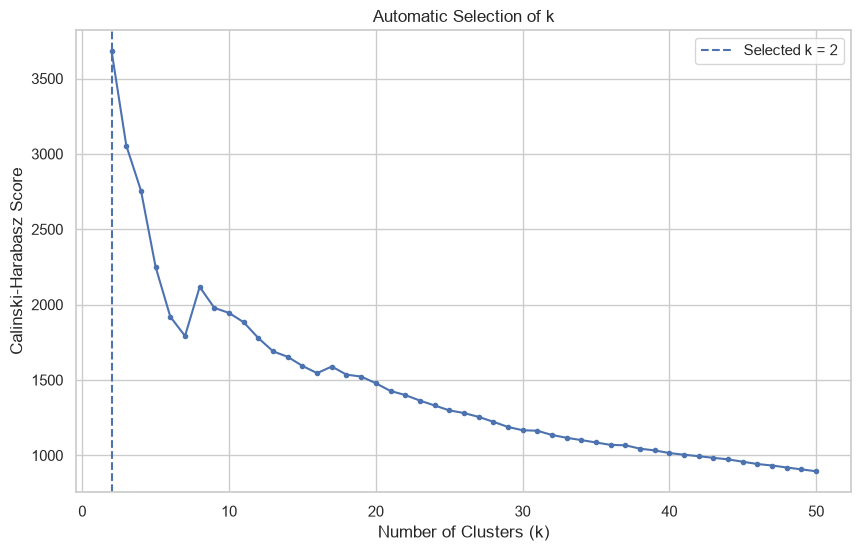

In [23]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    demo_ch_table["k"],
    demo_ch_table["CH Score"],
    marker="o",
    markersize=3
)

plt.axvline(
    demo_k,
    linestyle="--",
    label=f"Selected k = {demo_k}"
)

plt.xlabel(
    "Number of Clusters (k)"
)

plt.ylabel(
    "Calinski-Harabasz Score"
)

plt.title(
    "Automatic Selection of k"
)

plt.legend()
plt.grid(True)

plt.show()

In [27]:
monte_carlo_records = []

for iteration in range(1, 51):

    (
        selected_k,
        best_ch_score,
        cluster_labels,
        _
    ) = choose_k_with_ch(
        X_cluster,
        random_state=iteration
    )

    (
        predicted_labels,
        majority_table
    ) = assign_cluster_majority_labels(
        cluster_labels,
        Y_cluster
    )

    metrics = clustering_hamming_metrics(
        Y_cluster,
        predicted_labels
    )

    monte_carlo_records.append({
        "Iteration": iteration,
        "Selected k": selected_k,
        "CH Score": best_ch_score,
        "Hamming Distance":
            metrics["Hamming Distance"],
        "Hamming Score":
            metrics["Hamming Score"],
        "Hamming Loss":
            metrics["Hamming Loss"]
    })


monte_carlo_results = pd.DataFrame(
    monte_carlo_records
)

print(
    "Monte-Carlo simulation completed: 50/50 iterations."
)

Monte-Carlo simulation completed: 50/50 iterations.


In [28]:
monte_carlo_summary = pd.DataFrame({
    "Metric": [
        "Hamming Distance",
        "Hamming Score",
        "Hamming Loss"
    ],

    "Mean": [
        monte_carlo_results[
            "Hamming Distance"
        ].mean(),

        monte_carlo_results[
            "Hamming Score"
        ].mean(),

        monte_carlo_results[
            "Hamming Loss"
        ].mean()
    ],

    "Standard Deviation": [
        monte_carlo_results[
            "Hamming Distance"
        ].std(ddof=1),

        monte_carlo_results[
            "Hamming Score"
        ].std(ddof=1),

        monte_carlo_results[
            "Hamming Loss"
        ].std(ddof=1)
    ]
})

display(
    monte_carlo_summary
)

print(
    "\nFrequency of selected k:"
)

display(
    monte_carlo_results[
        "Selected k"
    ]
    .value_counts()
    .sort_index()
    .rename("Frequency")
    .to_frame()
)

,Metric,Mean,Standard Deviation
0,Hamming Distance,0.895622,1.121495e-16
1,Hamming Score,0.701459,1.121495e-16
2,Hamming Loss,0.298541,5.607473e-17



Frequency of selected k:


,Frequency
Selected k,
2,50


### 2(c) Monte-Carlo Results and Interpretation

The K-Means clustering procedure was repeated **50 times** using different random initializations.

For each Monte-Carlo run, the number of clusters \(k\) was selected automatically using the Calinski-Harabasz criterion. Each cluster was then assigned the majority Family, Genus, and Species labels of the observations belonging to that cluster.

The final results are:

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Hamming Distance | 0.895622 | \(1.121495\times10^{-16}\) |
| Hamming Score | 0.701459 | \(1.121495\times10^{-16}\) |
| Hamming Loss | 0.298541 | \(5.607473\times10^{-17}\) |

The selected number of clusters was

\[
\boxed{k=2}
\]

in all 50 Monte-Carlo runs.

---

### Selection of \(k\)

The frequency table shows that

\[
k=2
\]

was selected in

\[
50/50
\]

runs.

Thus, the Calinski-Harabasz criterion consistently identifies a two-cluster solution for the Anuran Calls MFCC data under this procedure.

This result is very stable with respect to the different K-Means random initializations used in the Monte-Carlo simulation.

However, the true data contain multiple Family, Genus, and Species categories. Therefore, two clusters are clearly too coarse to reproduce the entire biological label structure. The clusters instead appear to represent broader groupings in the MFCC feature space.

---

### Hamming Distance

The average Hamming distance is

\[
0.895622.
\]

Because each observation has three labels, the Hamming distance represents the average number of incorrect labels per observation.

Thus, on average, approximately

\[
0.896
\]

of the three labels are assigned incorrectly for each observation.

Equivalently, the average number of correctly assigned labels per observation is

\[
3-0.895622
= 2.104378.
\]

Therefore, K-Means correctly recovers approximately **2.10 of the 3 labels per observation on average**.

---

### Hamming Score

The mean Hamming score is

\[
0.701459.
\]

Therefore, approximately

\[
70.15\%
\]

of all individual Family, Genus, and Species labels are correctly assigned by the cluster-majority labeling procedure.

This indicates moderate agreement between the unsupervised K-Means clusters and the true biological labels.

---

### Hamming Loss

The mean Hamming loss is

\[
0.298541.
\]

Therefore, approximately

\[
29.85\%
\]

of all individual label assignments are incorrect.

As expected,

\[
\text{Hamming Score}
= 1-\text{Hamming Loss},
\]

because

\[
1-0.298541
= 0.701459.
\]

Also, since there are three labels,

\[
3\times0.298541
= 0.895623,
\]

which agrees with the reported average Hamming distance up to rounding.

---

### Stability Across the 50 Runs

The reported standard deviations are approximately

\[
1.12\times10^{-16}
\]

for Hamming Distance and Hamming Score, and

\[
5.61\times10^{-17}
\]

for Hamming Loss.

These values are effectively zero for practical purposes.

Therefore, all 50 Monte-Carlo runs produced essentially identical clustering performance.

Combined with the fact that \(k=2\) was selected in every run, this indicates extremely stable results under the current K-Means and Calinski-Harabasz procedure.

---

### Comparison with the Supervised Models

The unsupervised K-Means model performs substantially worse than the supervised classifiers developed in Question 1.

For example, the Gaussian SVM achieved

\[
\text{Hamming Score}=0.986259
\]

and

\[
\text{Hamming Loss}=0.013741.
\]

In contrast, K-Means achieves

\[
\text{Hamming Score}=0.701459
\]

and

\[
\text{Hamming Loss}=0.298541.
\]

This difference is reasonable because the SVM classifiers use the true labels during training, whereas K-Means forms clusters using only the MFCC features.

The labels are used only after clustering to determine the majority Family, Genus, and Species within each cluster.

In addition, consistently selecting only two clusters limits the ability of K-Means to represent the much richer multi-class label structure of the dataset.

### Conclusion

Across all 50 Monte-Carlo runs, the clustering procedure consistently selected

\[
\boxed{k=2}.
\]

The average clustering performance is:

\[
\boxed{\text{Hamming Distance}=0.895622}
\]

\[
\boxed{\text{Hamming Score}=0.701459}
\]

\[
\boxed{\text{Hamming Loss}=0.298541}.
\]

The near-zero standard deviations show that the results are extremely stable across random initializations.

However, the Hamming score of approximately **70.15%** is substantially lower than the supervised SVM results, indicating that a two-cluster K-Means solution does not capture the full Family–Genus–Species structure of the Anuran Calls dataset.

## 3. ISLR 12.6.2

The dissimilarities are:

\[
d_{12}=0.30,\quad
d_{13}=0.40,\quad
d_{14}=0.70,
\]

\[
d_{23}=0.50,\quad
d_{24}=0.80,\quad
d_{34}=0.45.
\]

---

### (a) Complete Linkage

Initially, the smallest dissimilarity is

\[
d_{12}=0.30.
\]

Therefore, observations 1 and 2 are fused first at height

\[
0.30.
\]

We now have the clusters

\[
\{1,2\},\quad \{3\},\quad \{4\}.
\]

For complete linkage, the distance between two clusters is the
**maximum** pairwise dissimilarity.

Therefore,

\[
d(\{1,2\},\{3\})
= \max(d_{13},d_{23})
= \max(0.4,0.5)
= 0.5.
\]

Also,

\[
d(\{1,2\},\{4\})
= \max(d_{14},d_{24})
= \max(0.7,0.8)
= 0.8.
\]

Meanwhile,

\[
d_{34}=0.45.
\]

Since

\[
0.45 < 0.50 < 0.80,
\]

observations 3 and 4 are fused at height

\[
0.45.
\]

We now have two clusters:

\[
\{1,2\}
\]

and

\[
\{3,4\}.
\]

Their complete-linkage distance is

\[
\max
\{
d_{13},
d_{14},
d_{23},
d_{24}
\}
\]

\[
= \max\{0.4,0.7,0.5,0.8\}
= 0.8.
\]

Thus the final fusion occurs at height

\[
0.80.
\]

Therefore, the complete-linkage fusion sequence is:

\[
\boxed{
(1,2)\text{ at }0.30
}
\]

\[
\boxed{
(3,4)\text{ at }0.45
}
\]

\[
\boxed{
(\{1,2\},\{3,4\})
\text{ at }0.80
}
\]

---

### (b) Single Linkage

Again, the smallest initial dissimilarity is

\[
d_{12}=0.30.
\]

Therefore, observations 1 and 2 merge first at height

\[
0.30.
\]

For single linkage, cluster distance is the **minimum**
pairwise dissimilarity.

Therefore,

\[
d(\{1,2\},3)
= \min(0.4,0.5)
= 0.4,
\]

and

\[
d(\{1,2\},4)
= \min(0.7,0.8)
= 0.7.
\]

We also have

\[
d(3,4)=0.45.
\]

Since

\[
0.40 < 0.45 < 0.70,
\]

observation 3 joins the cluster \(\{1,2\}\) at height

\[
0.40.
\]

We now have

\[
\{1,2,3\}
\]

and

\[
\{4\}.
\]

Their single-linkage distance is

\[
\min
\{
d_{14},
d_{24},
d_{34}
\}
\]

\[
= \min
\{
0.7,
0.8,
0.45
\}
= 0.45.
\]

Thus observation 4 joins the cluster at height

\[
0.45.
\]

Therefore, the single-linkage fusion sequence is:

\[
\boxed{
(1,2)\text{ at }0.30
}
\]

\[
\boxed{
(\{1,2\},3)\text{ at }0.40
}
\]

\[
\boxed{
(\{1,2,3\},4)
\text{ at }0.45
}
\]

---

### (c) Complete Linkage Cut into Two Clusters

For the complete-linkage dendrogram, the two clusters immediately
before the final fusion are

\[
\boxed{\{1,2\}}
\]

and

\[
\boxed{\{3,4\}}.
\]

Therefore, cutting the dendrogram to obtain two clusters gives:

\[
\boxed{
C_1=\{1,2\},
\qquad
C_2=\{3,4\}
}
\]

---

### (d) Single Linkage Cut into Two Clusters

For the single-linkage dendrogram, immediately before the final
fusion the clusters are

\[
\{1,2,3\}
\]

and

\[
\{4\}.
\]

Therefore:

\[
\boxed{
C_1=\{1,2,3\},
\qquad
C_2=\{4\}
}
\]

---

### (e) Equivalent Dendrogram

The left and right branches at any fusion can be exchanged without
changing the hierarchical clustering.

For example, an equivalent complete-linkage dendrogram can display
the leaves in the order

\[
4,\ 3,\ 2,\ 1
\]

instead of

\[
1,\ 2,\ 3,\ 4.
\]

The fusion heights remain exactly the same:

\[
(1,2)\text{ at }0.30,
\]

\[
(3,4)\text{ at }0.45,
\]

and

\[
(\{1,2\},\{3,4\})
\text{ at }0.80.
\]

Therefore, changing the horizontal positions of the branches does
not change the meaning of the dendrogram.

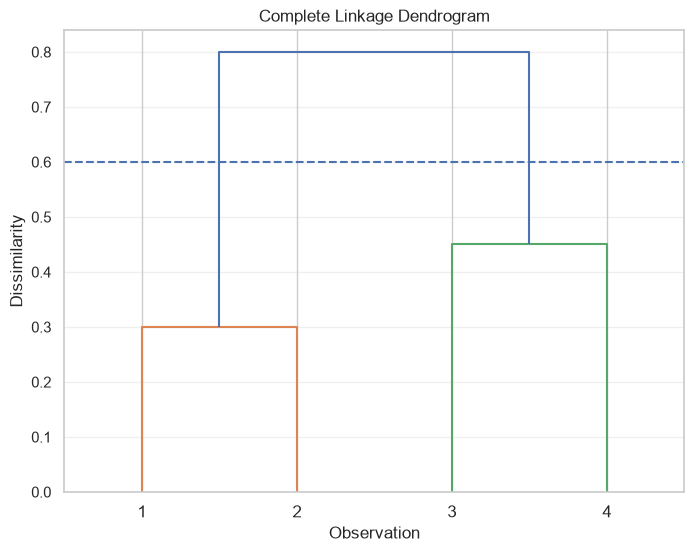

In [29]:
#Complete Linkage Dendrogram
complete_linkage = np.array([
    [0, 1, 0.30, 2],
    [2, 3, 0.45, 2],
    [4, 5, 0.80, 4]
])

plt.figure(
    figsize=(8, 6)
)

dendrogram(
    complete_linkage,
    labels=[
        "1",
        "2",
        "3",
        "4"
    ]
)

plt.xlabel(
    "Observation"
)

plt.ylabel(
    "Dissimilarity"
)

plt.title(
    "Complete Linkage Dendrogram"
)

plt.axhline(
    y=0.6,
    linestyle="--"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

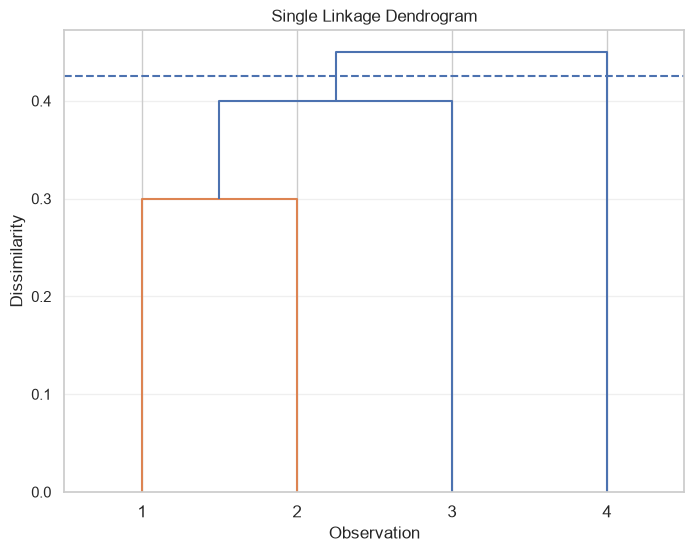

In [30]:
#Single Linkage Dendrogram
single_linkage = np.array([
    [0, 1, 0.30, 2],
    [4, 2, 0.40, 3],
    [5, 3, 0.45, 4]
])

plt.figure(
    figsize=(8, 6)
)

dendrogram(
    single_linkage,
    labels=[
        "1",
        "2",
        "3",
        "4"
    ]
)

plt.xlabel(
    "Observation"
)

plt.ylabel(
    "Dissimilarity"
)

plt.title(
    "Single Linkage Dendrogram"
)

plt.axhline(
    y=0.425,
    linestyle="--"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

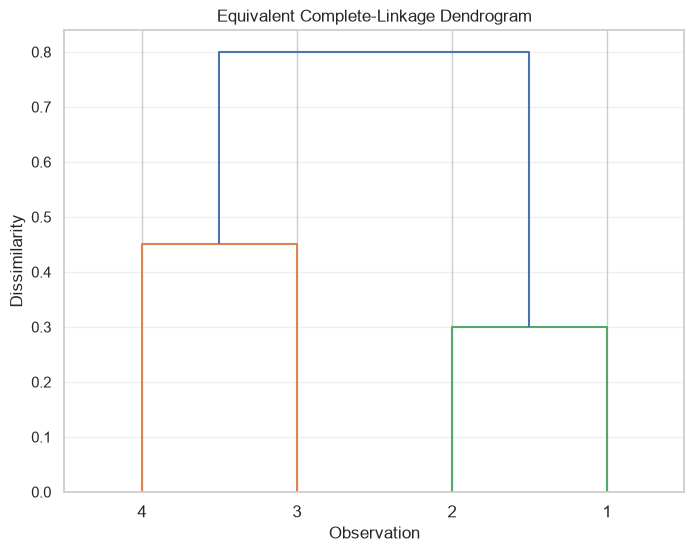

In [31]:
#Equivalent Dendrogram
complete_linkage_equivalent = np.array([
    # Swap 1 and 2
    [1, 0, 0.30, 2],

    # Swap 3 and 4
    [3, 2, 0.45, 2],

    # Swap the two main clusters
    [5, 4, 0.80, 4]
])

plt.figure(
    figsize=(8, 6)
)

dendrogram(
    complete_linkage_equivalent,
    labels=[
        "1",
        "2",
        "3",
        "4"
    ]
)

plt.xlabel(
    "Observation"
)

plt.ylabel(
    "Dissimilarity"
)

plt.title(
    "Equivalent Complete-Linkage Dendrogram"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()